# WAD2 G8T7: Training the HDB Resale Price Model

This Jupyter Notebook is a complete process workflow of how our group trained the price model used in our HDB Resale Finder app.

**What it does:** The model is trained to learn how much each feature of a flat (factors) affects its resale price, using multiple linear regression (compare how several independent variables would affect a single dependent variable) on log(price). The learned weights are saved for the app to use. 

One pooled model is trained on all sales in the 26 HDB towns of Singapore, with town and flat type as features, so the effect of lease, size and storey is measured fairly across all towns.

**Why Offline (not live in the app)?** HDB's data only changes monthly, so the model is trained once per month here. The app just reads the saved weights and estimates prices instantly.

**Input:** `raw/resale-prices.csv`, HDB "Resale flat prices based on registration date from
Jan-2017 onwards" (data.gov.sg), downloaded on 27 Oct 2026.

**Output:** `../server/data/priceModel.json`, the model's weights, read by the app.

**How to rerun (each month when HDB publishes new data):**
1. Download the latest CSV from data.gov.sg into `prep/raw/resale-prices.csv`
2. Select the `hdb-price` kernel (pandas, scikit-learn, matplotlib, ipykernel)
3. Restart the kernel and Run All
4. Check $R^2$ and MAE in Step 6, then commit the new `priceModel.json`

**Steps:**
1. Load & Filter the data
2. Choose & Build the features
3. Take log(price)
4. Split into training and test sets
5. Fit the regression
6. Check the accuracy ($R^2$, average error in dollars)
7. Read the weights: lease decay, town premiums and price trend
8. Export the weights for the app


## Step 0. Setup (one time, in a terminal at project root folder)

This notebook runs in its own conda environment so its packages do not clash with other projects.

We need to understand Anaconda, which bundles 3 things: 

1. Python
2. Conda, the tool which creates and switches the environments and also install packages.
3. Hundreds of pre-installed packages such as (pandas, numpy, matplotlib, Jupyter, etc)

Mainly, we need conda from Anaconda to be able to manage Python environments.

```bash 
conda create -n hdb-price python=3.12 -y 
```
**create:** create a new environment<br>
**-n hdb-price:** name is hdb-price<br>
**python=3.12:** python version<br>
**-y:** answer yes automatically when conda asks to proceed<br>
So, you are creating a new empty environment for this project.

```bash
conda activate hdb-price
```
It switches to that environment.
```
Original: (base) user-laptop
```
```
After: (hdb-price) user-laptop
```

```bash
pip install pandas scikit-learn matplotlib ipykernel
```

Install the various libraries needed into the active env (hdb-price). Hence why you activate the env before installing. 



In [193]:
import sys, pandas, sklearn
print(sys.executable) #show where the Python that's running this notebook is located
print(pandas.__version__, sklearn.__version__) #versions of pandas and sklearn

/Users/philbertwong/Downloads/WAD-G8-Group-7-project/.venv/bin/python
3.1.0 1.9.1


### Libraries used:

pandas, numpy, matplotlib

We need to import them.

In [194]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression



## Step 1a. Download and load the dataset

First, go to data.gov.sg and search 'resale hdb flat prices'. 

Next, download the dataset named: "Resale flat prices based on registration date from Jan-2017 onwards". 

Thirdly, rename the file as `resale-prices.csv` and put the file in `prep/raw/`. The file location should now be `prep/raw/resale-prices.csv`.

The date the dataset was downloaded for this notebook: 27 Oct 2026.

Now we need to import the pandas library so this notebook can use it.

We shall give it a short nickname 'pd', so it will be easier to write.


In [195]:
#using pandas here

df = pd.read_csv("raw/resale-prices.csv")
print(df.shape)
print(df.dtypes)
df.head()

(243874, 11)
month                      str
town                       str
flat_type                  str
block                      str
street_name                str
storey_range               str
floor_area_sqm         float64
flat_model                 str
lease_commence_date      int64
remaining_lease            str
resale_price           float64
dtype: object


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0


What each line does:

```
df = pd.read_csv("raw/resale-prices.csv")
```

This line opens the CSV file and turns it into a **DataFrame**, pandas's table object, with rows and columns like a spreadsheet. We use the path relative to the file, hence raw/ and not prep/raw/. It then stores the table in a variable named 'df' (short for DataFrame), which every later step uses.

```
print(df.shape)
```
This prints the table's size as rows and columns

```
print(df.dtypes)
```
This prints the data type of each column and tells us which column's values are numbers. We should see 3 kinds:
1. int64: whole number - lease_commence_date
2. float64: decimal number - floor_area_sqm, resale_price
3. object(or str): text - month, town, flat_type, block, street_name, storey_range, flat_model, remaining_lease

This matters because regression only works with numbers. Hence, we must convert each value into numbers. 

```
df.head()
```
This prints the first 5 rows so we can just see the what a subset of the data looks like. 



## Step 1b. Filter the data for all 26 towns

By running the code above, we can see that from `df.shape` and `df.head()`, the dataset has 243,874 sales. Our app covers all 26 HDB towns in Singapore, so the model is trained on all of them. The only sales we drop are the two flat types the app barely has: 1 ROOM and MULTI-GENERATION. They have too few sales (50 and 52 since Jan 2021) for the model to learn a reliable weight, so we keep the 5 common types (2 ROOM, 3 ROOM, 4 ROOM, 5 ROOM and EXECUTIVE).

**How we are going filter:** Make a True/False mask for every row by using `.isin()` to check whether the town is in our list of 26 towns (and, in the same way, whether the flat type is one of our 5 types). Then use `df[mask]` to keep only the rows marked True. 

**Simple Check:** Ensure the 'town' column only lists towns from our list of 26 towns.

In [196]:
TOWNS = [
    "ANG MO KIO", "BEDOK", "BISHAN", "BUKIT BATOK", "BUKIT MERAH", "BUKIT PANJANG", "BUKIT TIMAH",
    "CENTRAL AREA", "CHOA CHU KANG", "CLEMENTI", "GEYLANG", "HOUGANG", "JURONG EAST", "JURONG WEST",
    "KALLANG/WHAMPOA", "MARINE PARADE", "PASIR RIS", "PUNGGOL", "QUEENSTOWN", "SEMBAWANG", "SENGKANG",
    "SERANGOON", "TAMPINES", "TOA PAYOH", "WOODLANDS", "YISHUN",
]

in_list_towns = df["town"].isin(TOWNS)
df = df[in_list_towns]

# Keep the 5 common flat types (see the note below)
FLAT_TYPES = ["2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE"]
df = df[df["flat_type"].isin(FLAT_TYPES)]

print(df.shape)
df["town"].value_counts()



(243692, 11)


town
SENGKANG           19685
PUNGGOL            17634
WOODLANDS          17348
TAMPINES           16941
YISHUN             16457
JURONG WEST        15949
BEDOK              12733
HOUGANG            12309
CHOA CHU KANG      10925
BUKIT BATOK        10442
ANG MO KIO          9822
BUKIT MERAH         9190
BUKIT PANJANG       8644
TOA PAYOH           8080
KALLANG/WHAMPOA     7458
SEMBAWANG           7451
PASIR RIS           7053
QUEENSTOWN          6708
GEYLANG             6048
CLEMENTI            5372
JURONG EAST         4937
SERANGOON           4287
BISHAN              4253
CENTRAL AREA        1895
MARINE PARADE       1479
BUKIT TIMAH          592
Name: count, dtype: int64

It should print out 243692 rows and list out exactly the number of sales per town. 

### How have HDB resale prices changed over time across Singapore?

Before choosing which years to train our model on, we need to check how prices have moved over time. 

The year is the first 4 characters of "month", e.g. "2022-01"
We want to extract this:
```
df["year"] = df["month"].str[:4]
```

For each year, we need to find how many sales and the median price:

```
by_year = df.groupby("year")["resale_price"].agg(["count", "median"])
print(by_year)
```

**Why median?** We use the median not the mean because prices are right-skewed.

In [197]:
df["year"] = df["month"].str[:4]

by_year = df.groupby("year")["resale_price"].agg(["count", "median"]) #.agg is short for aggregate, which just means combine many values into one summary number
by_year["change_%"] = (by_year["median"].pct_change() * 100).round(1) #pct_change compares each year's median with the year before; turns it into a percentage and 1 dp
print(by_year)

      count    median  change_%
year                           
2017  20496  410000.0       NaN
2018  21537  408000.0      -0.5
2019  22161  400000.0      -2.0
2020  23315  425000.0       6.2
2021  29060  483000.0      13.6
2022  26698  525000.0       8.7
2023  25745  550000.0       4.8
2024  27815  590000.0       7.3
2025  25075  628000.0       6.4
2026  21790  633888.0       0.9


### Creating a chart displaying the median price per year

The above table after running the code is hard to read as a trend, so we plot the median price for each year as a line chart.

This makes it easier to see whether prices stayed flat, rose steadily, or changed direction, which decides which years to train the model on. 

We will use matplotlib to draw the chart:
- `plt.plot(x,y, marker="o")`: draws a line through the points, with a dot for each year
- `plt.title`, `plt.xlabel`, `plt.ylabel`: label the chart and both axes, x and y
- `plt.show()`: displays the chart below the cell

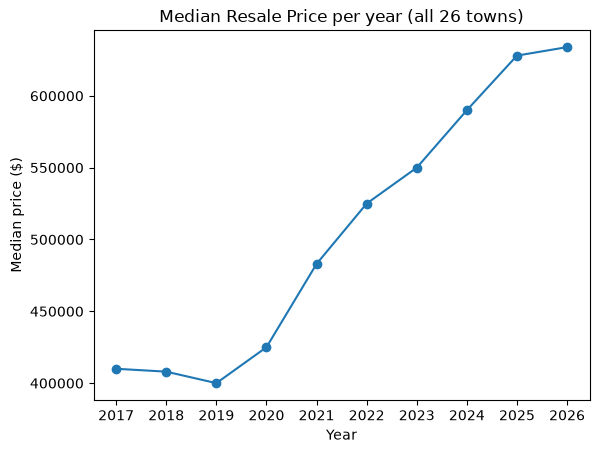

In [198]:
#using matplotlib.pyplot library here

plt.plot(by_year.index, by_year["median"], marker="o")
plt.title("Median Resale Price per year (all 26 towns)")
plt.xlabel("Year")
plt.ylabel("Median price ($)")
plt.show()

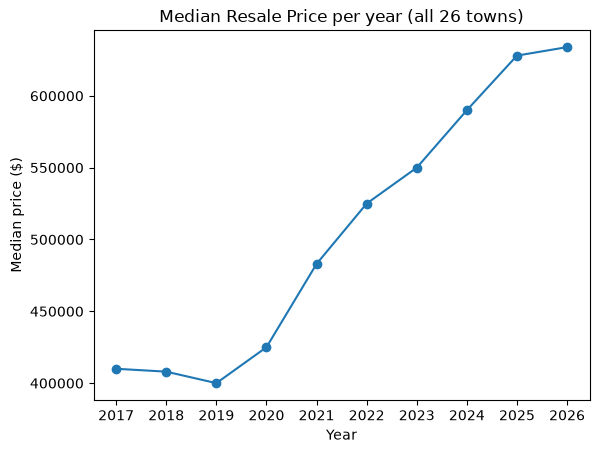

In [199]:
plt.plot(by_year.index, by_year["median"], marker="o")
plt.title("Median Resale Price per year (all 26 towns)")
plt.xlabel("Year")
plt.ylabel("Median price ($)")
plt.show()


From this chart, we can see the median resale flat prices of the "26 towns", "Singapore-wide" is flat from 2017 to 2020 at around \$455k, and rising steadily from 2021 (\$500k) to 2026 (\$689k).

As such, we can see prices behave differently in the two time periods, the next chart shows exactly where the change happens.

### Chart: Yearly % Change in Median Price

The line chart only shows the overall shape, but to choose an exact start year, we need to see how fast prices changed each year. The bar chart below shows each year's % change from the year before. Years before our chosen start year are grey; years we train on are blue.

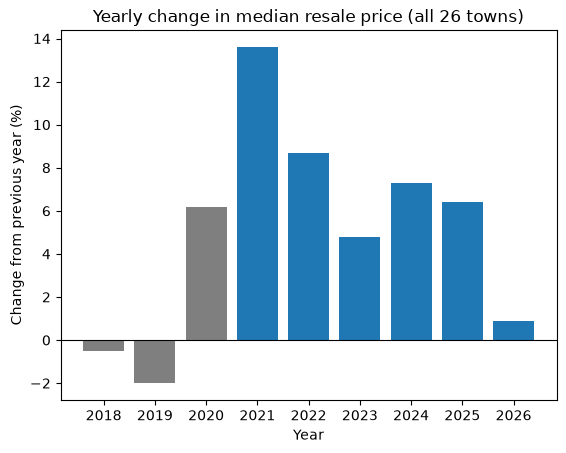

In [200]:
#Drop 2017 as it has no previous year so no % change
changes = by_year["change_%"].dropna()

#Colour each bar: grey before our start year, blue from it onwards
START_YEAR = "2021"
colours = []
for year in changes.index:
    if year >= START_YEAR:
        colours.append("tab:blue")
    else:
        colours.append("tab:grey")

plt.bar(changes.index, changes, color=colours)
plt.axhline(0, color="black", linewidth=0.8) #line at 0% so ups and downs are clear
plt.title("Yearly change in median resale price (all 26 towns)")
plt.xlabel("Year")
plt.ylabel("Change from previous year (%)")
plt.show()

**What the chart shows:** From 2018 to 2020 (grey), prices barely changed.<br>
From 2021, prices rose every year by about 5-10%.

**So we train from 2021:** It is the 1st year of the steady rise. Starting earlier would mix in the flat period; starting later (2022) would drop 2021, which rose at a similar pace.

## Step 1c. Keep only recent sales (from 2021 onwards)

In [201]:
START_MONTH = "2021-01"

#True/False for every row to check if this sale is on or after START_MONTH
is_recent = df["month"] >= START_MONTH

#Keep only the rows which return true
df = df[is_recent]

#Check
print(df.shape)
print(df["month"].min(), df["month"].max())

(156183, 12)
2021-01 2026-10


## Step 1d. Final Checks before building features

Before turning columns into numbrs, we check three things:

1. **Missing Values**: Rows with empty cells would break the regression.
2. **Flat Types**: Flat Types with very few sales can't be learned reliably.
3. **Prices**: The range should look like real HDB prices, with no obvious errors.

In [202]:
#1. Missing values per column (should be all 0)
print(df.isna().sum())

#2. Number of sales per flat type
print(df["flat_type"].value_counts())

#3. Summary of prices: Count, Mean, Spread, Min, Quartiles, Max
df["resale_price"].describe()


month                  0
town                   0
flat_type              0
block                  0
street_name            0
storey_range           0
floor_area_sqm         0
flat_model             0
lease_commence_date    0
remaining_lease        0
resale_price           0
year                   0
dtype: int64
flat_type
4 ROOM       67366
5 ROOM       37821
3 ROOM       36870
EXECUTIVE    10321
2 ROOM        3805
Name: count, dtype: int64


count    1.561830e+05
mean     5.901690e+05
std      1.936789e+05
min      1.500000e+05
25%      4.500000e+05
50%      5.600000e+05
75%      6.938880e+05
max      1.818000e+06
Name: resale_price, dtype: float64

### Based on the output, we can interpret that:

1. Missing Values are all 0. As such, there are no missing values and nothing to remove. 

2. For flat types, only the 5 common types are left. In Step 1b we already removed 1 ROOM and MULTI-GENERATION, which had very few sales, because the model is unable to learn a reliable weight from so few. 

3. For prices, most sales are between \$450k (25%) and \$694k (75%), with a median of \$560k. Since the mean (\$590k) is above the median (\$560k), this shows the data is skewed to the right, which we fix with log(price).



In [203]:
#Safety check: MULTI-GENERATION was already removed in Step 1b, so this removes nothing here
df = df[df["flat_type"] != "MULTI-GENERATION"]

#The year column is dropped, only needed for the chart above because the next step (the model's time feature) is built from `month` instead
df = df.drop(columns="year")

print(df.shape)


(156183, 11)


**Step 1d Summary:** 156,183 sales in all 26 towns from Jan-2021 to Oct-2026 of 5 flat types with no missing values.

**Why log(price):** For this project, we conducted multiple linear regression on log(price). The reason being that each weight becomes a percentage effect. 

Compare these two flats: 
- a 2-room in AMK at $232000 (Jan 2017, row 1 from raw)
- a 5-room in Bishan at $830000 (Jan 2017, row 147 from raw)

Supposed being 10 floors higher is worth about 5%. That is $11600 for the cheaper 2-room flat in AMK vs $41500 for the 5-room flat in Bishan. On raw prices, the model can only learn one fixed dollar amount for '10 floors higher' for every flat. Essentially, it is too much for the cheaper flat ($232k) and too little for the expensive flat ($830k) to move up higher. 

By conducting the linear regression on log(price):
Each weight becomes a percentage effect, so "+5%" applies naturally to both. 

**Skewed HDB Prices:** Additionally, HDB prices are skewed, with most of them being between $450k - $700k, but there is a long tail to the right that stretches all the way till $1.8M. This means the graph is lopsided and is skewed right (positively skewed).
The few very expensive flats pull the average (mean) up. 
**Note: This is for all 26 towns, Jan 2021 to Oct 2026.**

**How Log(price) solves the issue of Skewed HDB Prices:** Log measures by ratio, not by difference. Eg. $300k -> $600k and $600k -> $1.2M are both a gap of 0.69 in log because both are doubling.

Log turns "times 2" into "plus the same amount".
This balances the lopsided shape. 

**What are Residuals:** For every sale in the data, the model makes a guess, and we compare it with the real price: 
error = real price - predicted price

Example: a flat really sold for $650k but the model guessed $620k, so the error is +$30k (the model guessed too low.) 

**How does the model choose its weights?:** Linear Regression calculates the set of weights where: 
(error₁)² + (error₂)² + (error₃)² + …   is as **SMALL** as possible
**This is called least squares.**
**Why square?**
* So negative and positive errors don't cancel out. 
* To punish big mistakes more: being $60k off counts 4x as much as $30k off, not 2x.

## Step 2. Building the features

Linear Regression can only learn from **numbers**, and not text. It predicts the price by multiplying each feature by a weight and adding them up. (e.g. 0.005 x storey). So, we need to turn each column we want to use into a number (a feature) that the model can learn from.

## Step 2a. Storey

Higher floors usually sell for more: better views, more breeze, less noise from the street. So the floor is a factor the model should learn. E.g. "each extra floor adds about X% to the price."

From the data, we can see that HDB only records a 3-floor band from the column **storey_range**, not the exact floor. The model needs one number per flat, so we use the middle floor as the best single estimate as it is never more than 1 floor away from the real floor. 

So we split the floor band at " TO " and turn both numbers into integers and take their average. 


In [204]:
#2a. Storey: "10 TO 12" -> 11 (middle floor of the band)

#Split each band into 2
storey_parts = df["storey_range"].str.split(" TO ") #working on a whole column so u need .str

#First piece = lowest floor, second = highest; turn both into whole numbers
low = storey_parts.str[0].astype(int)
high = storey_parts.str[1].astype(int)

df["storey"] = (low + high) / 2

#Check text band next to the new number
df[["storey_range", "storey"]].head(10)


,storey_range,storey
87589,01 TO 03,2.0
87590,07 TO 09,8.0
87591,04 TO 06,5.0
87592,04 TO 06,5.0
87593,01 TO 03,2.0
87594,07 TO 09,8.0
87595,04 TO 06,5.0
87596,04 TO 06,5.0
87597,07 TO 09,8.0
87598,04 TO 06,5.0


In [205]:
#count how many sales there are on each floor, and list the floors from lowest to highest
df["storey"].value_counts().sort_index()

storey
2.0     26940
5.0     35545
8.0     32632
11.0    29042
14.0    15396
17.0     7277
20.0     3153
23.0     2139
26.0     1426
29.0      941
32.0      569
35.0      480
38.0      362
41.0      171
44.0       63
47.0       36
50.0       11
Name: count, dtype: int64

**Result:** Each Storey Band is now 1 number in the new column `storey` (e.g. "01 TO 03" -> 2)

- There are 17 different storeys, from floor 2 to 50, all 3 apart, with no odd values.
- Most sales are from floor 2 to 11 (26940 + 35545 + 32632 + 29042) / 156,183 = 0.795 (~80%), floors 14 to 17 is (15396 + 7277) / 156,183 = 0.145 (~15%), floor 20 and above is the remaining 6%. Hence, the storey effect is most reliable for low and middle floors.

## Step 2b. Remaining Lease: years left at the time of sale

HDB flats have a 99-year lease. The less lease is left, the less a flat is worth (fewer years left for the buyer, and banks lend less on short leases). This is called **Lease Decay**, so the model needs the years of lease left when each flat is sold. From this feature, the model learns how much the price changes for each extra year of lease left, holding the other features fixed.

**Why calculate it ourselves instead of just using the `remaining_lease` column?** This is because `remaining_lease` text is not consistent (E.g. 61 years and 62 years 08 months), and our app only knows each block's **Lease Start Year**. Hence, we calculate it the same way the app can:

```
lease left = 99 - (time of sale - year the lease started)
```

In [206]:
#2b. Remaining lease at the time of sales, in years

#We need to extract the sale year and month e.g. "2023-08"
sale_year = df["month"].str[:4].astype(int)
sale_month = df["month"].str[5:].astype(int)

#Time of sale as a decimal year, e.g. Aug 2023 -> 2023 + 7/12 = 2023.58, sale_month - 1 because you count it as months that already passes, so for e.g January counts as 0 months not 1
sale_time = sale_year + (sale_month - 1) / 12

df["lease_years"] = 99 - (sale_time - df["lease_commence_date"])

#Check the number next to HDB's text for a few rows
df[["month", "lease_commence_date", "remaining_lease", "lease_years"]].head(10)


,month,lease_commence_date,remaining_lease,lease_years
87589,2021-01,1986,64 years 01 month,64.0
87590,2021-01,1986,64 years 01 month,64.0
87591,2021-01,1981,59 years,59.0
87592,2021-01,1980,58 years 02 months,58.0
87593,2021-01,1980,58 years 01 month,58.0
87594,2021-01,1986,64 years 02 months,64.0
87595,2021-01,1980,58 years 02 months,58.0
87596,2021-01,1981,59 years 01 month,59.0
87597,2021-01,1986,64 years,64.0
87598,2021-01,1976,54 years 04 months,54.0


In [207]:
#Summary of lease years left across all sales, rounded to 1 d.p.
df["lease_years"].describe().round(1)

count    156183.0
mean         73.1
std          15.0
min          38.2
25%          60.4
50%          72.8
75%          89.2
max          97.0
Name: lease_years, dtype: float64

**Result:** There is a new column `lease_years`, the years of lease left at the time of each sale. 

Based on the results, we can see that the lease left ranges from 38.2 to 97.0 years, with a median of 72.8 years.

The spread is wide as a quarter of sales have under 60.4 years left and a quarter have over 89.2 years. This wide range is what lets the model measure lease decay. 

## Step 2c. Time: months since Jan 2021

Prices rose steadily over our training period (Step 1). Without a time feature, the model is unable to tell a 2021 sale from a 2026 sale and would wrongly credit the price rise is to other features. Hence, we need to count each sale's month so the model is able to learn from the data and predict how much prices change per month, providing a predicted price trend. 

months since start = (sale year - 2021) x 12 + (sale month - 1) 

In [208]:
#2c. Time: months since START_MONTH (Jan 2021), e.g. for 2023-08, it will be 31 months since Jan 2021

# The first year of our data, taken from START_MONTH so the 2 always match
start_year = int(START_MONTH[:4])

#Years since the start (in months) + months into that year
df["months_since_start"] = (sale_year - start_year) * 12 + (sale_month - 1)

#Check each month once, next to its number
df[["month", "months_since_start"]].drop_duplicates().head(10)

,month,months_since_start
87589,2021-01,0
90080,2021-02,1
92240,2021-03,2
94683,2021-04,3
97016,2021-05,4
98973,2021-06,5
101275,2021-07,6
103934,2021-08,7
106673,2021-09,8
109189,2021-10,9


In [209]:
#range check
print(df["months_since_start"].min(), df["months_since_start"].max())

0 69


**Result:** The new column `months_since_start` shows the number of months since Jan 2021 for each sale. 

It runs from 0 (Jan 2021) to 69 (Oct 2026), going up by 1 each month (e.g. Feb 2021 -> 1)

This lets the model learn the price trend as a % change per month, which we can later turn into \$ per year. 

## Step 2d. Floor area: log(area)

Bigger flats cost more, so floor area is a key feature. We use **log(area)** instead of raw sqm because size matters in proportion: Going from 50 to 60 sqm (+20%) is a much bigger change than 130 to 140 sqm (+8%). With log(area), the weight means "% change in price for a 1% bigger flat", which is the same for flats of all sizes.

This also means our lease effect can be read as the effect on **price per sqm**.

In [210]:
#2d. Floor area: log of the floor area in sqm
#using numpy here

df["log_area"] = np.log(df["floor_area_sqm"])

#check area next to its log
df[["floor_area_sqm", "log_area"]].head(10)

,floor_area_sqm,log_area
87589,45.0,3.806662
87590,45.0,3.806662
87591,68.0,4.219508
87592,68.0,4.219508
87593,68.0,4.219508
87594,60.0,4.094345
87595,68.0,4.219508
87596,68.0,4.219508
87597,60.0,4.094345
87598,73.0,4.290459


In [211]:
#Range check: floor area and its log
df[["floor_area_sqm", "log_area"]].describe().round(2)

,floor_area_sqm,log_area
count,156183.00,156183.00
mean,96.15,4.53
std,23.82,0.26
min,34.00,3.53
25%,79.00,4.37
50%,93.00,4.53
75%,112.00,4.72
max,366.70,5.90


**Result:** This creates a new column `log_area`, which is the log of the floor area. 

**Interpretation of data:** Floor area ranges from 37 to 243 sqm, and the median is 93 sqm, so `log_area` ranges from 3.61 to 5.49. <br>
As you can see from the data, the largest flat is about 6.57x the smallest, but its log is only about 1.5x bigger. That is the "in proportion" effect we want, the log squeezing the range.

## Step 2e. Town and Flat Type

We know that location of a HDB flat and the flat type affects the price. Bishan is a pricier location compared to Punggol, and a 5-room costs more than a 3-room. The model needs this information as numbers, but currently they're categories (names), not amounts.

### How do we turn a name into numbers?

If we were to number them (AMK=1, Bedok=2, Bishan=3, and so on up to Yishun=26) it would treat the towns as amounts which is meaningless, because towns have no order. <br>
Instead, we do one-hot encoding, which is one 0/1 column per category. Each town gets its own on/off switch, and its switch gets its own weight e.g. "being in Bishan adds +X% to the price".

Instead of having all 26 town columns, we use AMK as the **baseline.**

**Why is that?** 
- This is because it isn't needed. If all 25 switches are 0, the flat must be in AMK and a 26th column would add no new information.
- It would break the model because the 26 columns always add up to 1 for every row, which exactly copies the model's starting value (the intercept). The model then can't tell them apart, and the weights become unstable. This is called the **dummy variable trap**.

**What the baseline means for reading the weights:** Every town weight is compared with AMK. `town_BISHAN` = +0.15 means a Bishan flat costs about 15% more than an otherwise identical AMK flat. The same goes for flat type: the baseline is 2 ROOM, so `flat_type_5 ROOM` is compared with a 2 ROOM of the same size and lease.

In [212]:
#2e. Town and flat type -> converted to 0/1 columns with the 1st category left out as the baseline
df = pd.get_dummies(df, columns=["town", "flat_type"], drop_first=True, dtype=int) #we want to drop the 1st category, so drop_first=True

#check the new 0/1 columns
new_columns = [col for col in df.columns if col.startswith("town_") or col.startswith("flat_type_")]
print(new_columns)
df[new_columns].head()


['town_BEDOK', 'town_BISHAN', 'town_BUKIT BATOK', 'town_BUKIT MERAH', 'town_BUKIT PANJANG', 'town_BUKIT TIMAH', 'town_CENTRAL AREA', 'town_CHOA CHU KANG', 'town_CLEMENTI', 'town_GEYLANG', 'town_HOUGANG', 'town_JURONG EAST', 'town_JURONG WEST', 'town_KALLANG/WHAMPOA', 'town_MARINE PARADE', 'town_PASIR RIS', 'town_PUNGGOL', 'town_QUEENSTOWN', 'town_SEMBAWANG', 'town_SENGKANG', 'town_SERANGOON', 'town_TAMPINES', 'town_TOA PAYOH', 'town_WOODLANDS', 'town_YISHUN', 'flat_type_3 ROOM', 'flat_type_4 ROOM', 'flat_type_5 ROOM', 'flat_type_EXECUTIVE']


,town_BEDOK,town_BISHAN,town_BUKIT BATOK,town_BUKIT MERAH,town_BUKIT PANJANG,town_BUKIT TIMAH,town_CENTRAL AREA,town_CHOA CHU KANG,town_CLEMENTI,town_GEYLANG,...,town_SENGKANG,town_SERANGOON,town_TAMPINES,town_TOA PAYOH,town_WOODLANDS,town_YISHUN,flat_type_3 ROOM,flat_type_4 ROOM,flat_type_5 ROOM,flat_type_EXECUTIVE
87589,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
87590,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
87591,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
87592,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
87593,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


**Result:** `town` and `flat_type` are replaced by 29 columns: 25 for towns, 4 for flat types.

AMK and 2 ROOM are the baselines (no column), so their effect is built into the starting value and every other town and flat type is measured against them.

## Step 3. Building the output the model learns to predict: The target - log(price)

In Step 2, the inputs (features) was built. Now we build what the model predicts, the **target**. <br>
We predict the **log(resale_price)** instead of the price itself.

The histograms and skew numbers below show the skew before and after taking the log.

In [213]:
#3. Target: log of the resale_price
df["log_price"] = np.log(df["resale_price"])

#check price next to its log
df[["resale_price", "log_price"]].head(10)

,resale_price,log_price
87589,211000.0,12.259613
87590,225000.0,12.323856
87591,260000.0,12.468437
87592,265000.0,12.487485
87593,265000.0,12.487485
87594,268000.0,12.498742
87595,268000.0,12.498742
87596,270000.0,12.506177
87597,275000.0,12.524526
87598,275888.0,12.527750


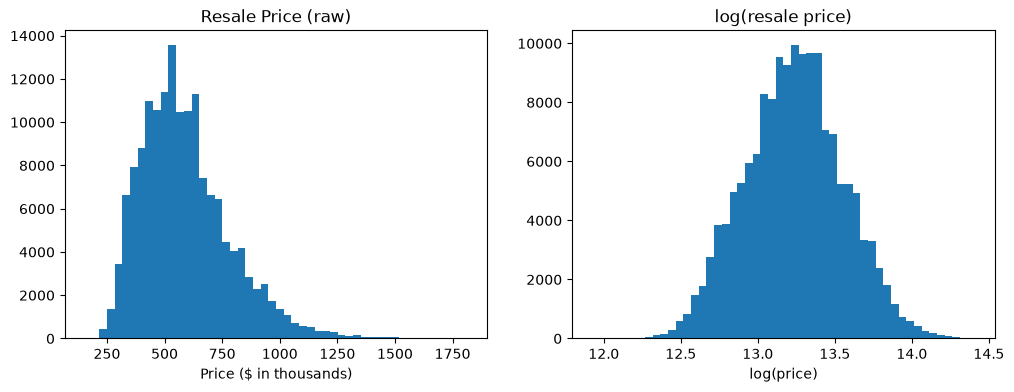

Skew of raw price: 0.97
Skew of log price: 0.06


In [214]:
#Histograms: raw price vs log(price), side by side
fig, axes = plt.subplots(1,2, figsize=(12, 4))

#histogram for raw price
axes[0].hist(df["resale_price"] / 1000, bins=50)
axes[0].set_title("Resale Price (raw)")
axes[0].set_xlabel("Price ($ in thousands)")

#histogram for log price
axes[1].hist(df["log_price"], bins=50) #only raw price needs to divide by 1000. log_price is already a small number
axes[1].set_title("log(resale price)") 
axes[1].set_xlabel("log(price)")

plt.show()

#skew: 0 = symmetric, + = long right tail
print("Skew of raw price:", round(df["resale_price"].skew(), 2))
print("Skew of log price:", round(df["log_price"].skew(), 2))


**Result:** New column `log_price` is the target the model will predict.

The raw prices have a long right tail (skew 0.97): most flats sell between \$450k and \$694k. <br>
After taking the log, the shape is roughly symmetric (skew 0.06), so the few expensive flats no longer pull the model around.

To turn a prediction back into dollars, we undo the log with `np.exp`, e.g. `np.exp(13.24)` $\approx$ \$562k, which is close to the median price of \$560k.

## Step 4. Train/Test Split

To check the model honesly, we hide some sales before training, like keeping exam questions the student hasn't seen. 
- **Training Set (80%):** the model learns its weights from these sales
- **Test Set (20%):** the model has never seen this test set during training. We use this in Step 6 to check how close the predictions are to the real prices.

**X** = the 33 features (inputs), **y** = `log_price` (the target) <br>
Capital X because the features are a table (matrix) with many columns, lowercase y because the target is a single column (vector). It's the standard ML naming convention.

The feature list is written once in `FEATURES`, so the same order is used when we export the weights for the app.

We also need to implement a computer's "random" shuffle using `random_state=x`, where x is a seed, which decides the order it comes out in  (same seed, same order). This makes the shuffle the same every time the notebook is run. 

**Without it:** `train_test_split` shuffles all the 156,183 sales randomly before splitting, which comes from the seed (x). <br>
Without the seed, every run gives a different 20% (31,237 sales) into the test set.

E.g. think of shuffling a deck of cards and dealing 20% of them into a "test" pile. Without random_state: every time you run the notebook, the deck is shuffled differently. Because the model learns from a slightly different 80% each time, and is tested on a slightly different 20%, your numbers wobble a little on every run, and this creates the problem of the numbers captured in the result cell not matching the set of numbers in the next run.

Hence, `random_state=x` fixes the shuffle, so every re-run gives the same split and results.

In [215]:
#4. Train/Test Split 

#the 33 features
FEATURES = ["storey", "lease_years", "months_since_start", "log_area"] + new_columns

X = df[FEATURES]
y = df["log_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2 , random_state=42)

print("Features:", len(FEATURES))
print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Features: 33
Train: (124946, 33)
Test:  (31237, 33)


### Why do we not use validation for this model?

In order to understand why we do not use validation for this model, we need to first understand what a validation set is for.

**What a validation set is for:** Tuning choices before the final test. Validation in ML is the structured process of evaluating how well a trained model generalises to new, unseen data rather than just memorising its training dataset. Some other models have settings you have to pick e.g. how deep a decision tree goes, or how strongly to penalise big weights. Through this, you try different settings, score each one on the validation set, keep the best, and then check it once on the test set. The test set has to stay untouched, so you need a 3rd set for that trial-and-error.

**Why we do not need one in this case:** 
- Plain linear regresion has no settings to tune. Least squares calculates the one best set of weights directly. There's nothing to try out.
- We're not comparing several models, just using one pooled model. 

## Step 5. Fit the model

This is the step where the model learns and where the regression actually happens.

The model predicts:

log_price = intercept + w1 x storey + w2 x lease_years + w3 x months_since_start + ... + w33 x flat_type_EXECUTIVE

**Fitting** finds the intercept and the 33 weights that make the predicted log_price as close as possible to the real log_price for the training sales (smallest sum of squared errors, i.e. least squares). We fit on the **training set only** while the test set stays hidden until Step 6.

The whole model is essentially just these 34 numbers and what we export for the app.

In [216]:
#5. Fit the model on the training set only

model = LinearRegression()
model.fit(X_train, y_train)

#the learnt numbers: 1 intercept + 33 weights (same order as FEATURES)
print("Intercept:", round(model.intercept_, 3)) #model.intercept_ is the starting value the model learned
weights = pd.Series(model.coef_, index=FEATURES) #pairs each number with its name
weights.round(4)


Intercept: 8.594


storey                  0.0077
lease_years             0.0100
months_since_start      0.0057
log_area                0.8261
town_BEDOK             -0.0333
town_BISHAN             0.1534
town_BUKIT BATOK       -0.1827
town_BUKIT MERAH        0.1272
town_BUKIT PANJANG     -0.2337
town_BUKIT TIMAH        0.2739
town_CENTRAL AREA       0.2408
town_CHOA CHU KANG     -0.2981
town_CLEMENTI           0.0426
town_GEYLANG            0.0509
town_HOUGANG           -0.1273
town_JURONG EAST       -0.1658
town_JURONG WEST       -0.2535
town_KALLANG/WHAMPOA    0.0867
town_MARINE PARADE      0.2061
town_PASIR RIS         -0.1534
town_PUNGGOL           -0.2160
town_QUEENSTOWN         0.1354
town_SEMBAWANG         -0.2734
town_SENGKANG          -0.2342
town_SERANGOON          0.0298
town_TAMPINES          -0.0749
town_TOA PAYOH          0.0639
town_WOODLANDS         -0.2624
town_YISHUN            -0.1958
flat_type_3 ROOM        0.0039
flat_type_4 ROOM        0.0181
flat_type_5 ROOM        0.0370
flat_typ

## Step 6a. How good is the model for the app? (How accurate the model is)

We test the model on the **31,237 test sales** it has never seen, and compare its predictions with the real prices.

The starting question: flat prices in the dataset differ a lot, from \$150k to \$1.82M. Hence, how much of that difference can the model explain?

**Part A: The "no model" guess** <br>
Imagine you knew nothing about a flat and had to guess its log price. The best single guess is the average. Now we need to measure how wrong that guess is across all the sales:

**total error** = the sum of $(real - average)^2$

This is all the price variation the model needs to explain.

**Part B: the model's guess**<br>
Now use the model, which knows the storey, lease, town, size, etc and measure its errors: <br>

**model error** = the sum of $(real - predicted)^2$

These are the squared errors that least squares made as small as possible.

**Part C. Calculate $R^2$**

$R^2$ = 1 - (model error $\div$ total error)

This compares the model with guessing the average, and the result is $R^2$. 

**Part D. Compare train vs test $R^2$ (Overfitting Check)**

We want the model to be good at predicting sales it has never seen, because the app predicts prices for flats the model didn't train on. We do not want "overfitting", which is the term for the model being good at sales it has already seen and thus memorised. 

Ideally, we want the gap to be small (close to 0) between the two $R^2$ to ensure no overfitting. 

**How to read the gap between train $R^2$ vs test $R^2$:**
- About the same: the model learned real patterns that carry over to new sales
- train $R^2$ is much higher: it memorised the training sales
- test slightly higher than train: fine, just the luck of the split.

In [217]:
#6a. overfitting check

r2_train = model.score(X_train, y_train)
r2_test = model.score(X_test, y_test)

print("R² train:", round(r2_train, 3))
print("R² test:", round(r2_test, 3))
print("Gap:", round(r2_train - r2_test, 3))



R² train: 0.904
R² test: 0.904
Gap: 0.0


**Result:** $R^2$ = 0.904 on both train and test sales, so the features explain about 90% of the differences in log(price).

The gap is 0.0, so the model trained isn't overfitting and does well on the test set of flats it has never seen before.

## Step 6b. Error in dollars (Mean Absolute Error; MAE)

Although in Step 6a, the features explain 90% of the differences in log(price), a buyer would still want to know how many dollars off a prediction is. So we:

1. Predict the log price for each of the 31,237 sales
2. Turn both the predicted and the real values back into dollars with `np.exp`. The model works in log, but errors need to be in \$ to mean anything.
3. Miss = |real - predicted| (abs drops the sign), so e.g. \$30k too high or too low still counts as a \$30k miss.
4. Average the misses (**MAE**), and also take the median and % miss.

In [218]:
#6b. Error in dollars on the test set

pred_log = model.predict(X_test) #predicted log price for each test sale

pred_price = np.exp(pred_log) #back to dollars
real_price = np.exp(y_test)

miss = abs(real_price - pred_price)  #shows how far off each prediction

print("MAE: $", round(miss.mean()))
print("Median miss: $", round(miss.median()))
print("Average % error:", round((miss / real_price).mean() * 100, 1), "%")
print("Within 10% of real price:", round(((miss / real_price) < 0.10).mean() * 100, 1), "%")

MAE: $ 46315
Median miss: $ 34898
Average % error: 7.8 %
Within 10% of real price: 70.5 %


**Result:** On sales it has never seen before, the model is off by \$46,315 on average, with a median miss of \$34,898, about 7.8% of the price.

About 70.5% of predictions are within 10% of the real price. 

The average is higher than the median because a few large misses on expensive flats pull it up (the same right skew as the prices).

## Step 6c. Baseline: Is \$46k off actually good?

"\$46k off" means nothing on its own. To judge whether the error is impressive or terrible, we compare it with the simplest reasonable guess, the median training price for every flat and ignore everything else about the flat (storey, lease, town, size, etc).

In [219]:
# 6c. baseline: guess the median training price for every test flat

baseline_guess = np.exp(y_train).median()
baseline_miss = abs(real_price - baseline_guess)

print("Baseline guess: $", round(baseline_guess))
print("Baseline MAE: $", round(baseline_miss.mean()))
print("Model MAE: $", round(miss.mean()))
print("Model is", round(baseline_miss.mean() / miss.mean(), 1), "x better")

Baseline guess: $ 560000
Baseline MAE: $ 148455
Model MAE: $ 46315
Model is 3.2 x better


**Result:** Guessing the median price (\$560k) for every flat is off by \$148,455 on average. <br>
The model is off by \$46,315, about 3.2x smaller, so the features (storey, lease, time, size, town, flat type) explain most of what drives the price.

## Step 7a. What do the weights from Step 5 tell us about HDB prices?

The weights are currently on the log scale, so we turn them into % effects on price:

**% effect = $(e^{weight} - 1) \times 100$** 

Weight x 100 only works for small weights because it ignores compounding. For bigger weights like 'Bishan' or 'Executive' it's off by a few %, so we use the exact (e^w - 1) for all of them. 

`log_area` is the exception: both sides are logs, so its weight already means "1% bigger flat -> weight % higher price".

In [220]:
#7a. turn each weight into a % effect except log_area

other_weights = weights.drop("log_area")
pct_effect = (np.exp(other_weights) - 1) * 100

effects = pd.DataFrame({"weight": other_weights, "% effect": pct_effect})
effects.round(4)

,weight,% effect
storey,0.0077,0.7726
lease_years,0.0100,1.0033
months_since_start,0.0057,0.5719
town_BEDOK,-0.0333,-3.2720
town_BISHAN,0.1534,16.5839
town_BUKIT BATOK,-0.1827,-16.6966
town_BUKIT MERAH,0.1272,13.5687
town_BUKIT PANJANG,-0.2337,-20.8406
town_BUKIT TIMAH,0.2739,31.5080
town_CENTRAL AREA,0.2408,27.2210


## Step 7b. Headline effects  in % and \$

From the table above, we pick out four effects relevant to a buyer's trade-off:

- **Storey Level:** % change for 1 storey/floor higher.
- **Remaining Lease (Lease Decay):** % change for 1 more year of lease left.
- **Market Trend:** % change per year. The weight is per month, so we multiply by 12 on the log scale before converting.
- **Flat size:** % change for a 10% bigger flat (`log_area` uses a power instead of $e^{w}$, because area is also a log)

To show them in dollars, we apply each % to a typical flat: the median training price from Step 6c (\$560k).

Because this is multiple linear regression (all 33 features fitted together), each effect is all else equal: the change in price from that one feature, with the other features held the same.

In [221]:
#7b. Headline effects in % and $, for a typical flat
typical_price = baseline_guess

per_floor = (np.exp(weights["storey"]) -1) * 100
per_lease_year = (np.exp(weights["lease_years"]) - 1) * 100
per_year_trend = (np.exp(weights["months_since_start"] * 12) - 1) * 100
area_10pct = (1.10 ** weights["log_area"] - 1) * 100

print("1 floor higher: +", round(per_floor, 2), "% ≈ $", round(per_floor / 100 * typical_price))
print("1 more lease year: +", round(per_lease_year, 2), "% ≈ $", round(per_lease_year / 100 * typical_price))
print("Trend per year: +", round(per_year_trend, 2), "% ≈ $", round(per_year_trend / 100 * typical_price))
print("10% bigger flat: +", round(area_10pct, 2), "%")

1 floor higher: + 0.77 % ≈ $ 4327
1 more lease year: + 1.0 % ≈ $ 5619
Trend per year: + 7.08 % ≈ $ 39662
10% bigger flat: + 8.19 %


**Result (all else equal, \$560k flat):** 

- **Floor Height:** each floor higher adds about 0.77% (\$4,327)
- **Lease Decay:** each extra year of lease left adds about 1.00% (\$5,619), so a flat loses about 1% of its value per year of lease used up.
- **Trend per year:** prices rose about 7.08% per year from Jan 2021 to Oct 2026 (\$39,662 a year); this is based on past growth, not a forecast.
- **Size:** a 10% bigger flat costs about 8.19% more, so bigger flats are cheaper per sqm. 

However, there are **limits** from the findings. 

### Limit 1: Lease Decay is one straight % per year

The model says every year of lease is worth about 1.00%, whether the flat has 90 years left or 50. This happens because `lease_years` is one feature with one weight, and a single weight can only give a constant % per year, it can't bend.

Yet, the **reality** is that decay in this case likely isn't constant. Going from 95 to 94 years left barely matters to buyers. However, at around 50 years left, it matters more because the lease is getting close to running out and loans and CPF rules become stricter for short leases. So the real curve is likely flat at first and then steeper later.

For this project, we decided to keep lease decay as one % per year because the dataset only has leases from 38 to 97 years, and also because the effect would be easier to read and explain. A next step would be to let the curve bend e.g. adding $\text{lease\_years}^2$, or separate weights for lease bands and check with cross-validation whether it improves accuracy.

### Limit 2: One trend for all 26 towns

The model says that prices rose 7.08% per year in all 26 towns.

This is because we are using a pooled model and there is only one `months_since_start` weight shared by every town. The town only shifts the price level and doesn't reflect the growth rate of each town individually.

The **reality** is that towns may have grown at different speeds. A newer town like Punggol may have risen faster or slower than Bishan.

However, we felt that using a pooled model for this project was acceptable because the app's main need is a good price estimate per block and using all 156,183 sales to estimate one stable trend already does that. If we were to split them into 26 smaller groups with different trends, each trend would be estimated from fewer sales, so it would be less reliable and more easily swayed by a few unusual sales.

For future work, we could add town $\times$ time features (a separate trend weight per town), or fit per-town models and do cross-validation.




## Step 8a. Export priceModel.json

Since our app runs JavaScript and not Python, the whole number is but just 12 numbers.

We save them to `server/data/priceModel.json`, and the app predicts a price with the same sum as Step 5, then turns it back into dollars with `Math.exp`.

Town and flat type effects are saved by name (e.g. "BISHAN"), matching the `town` and `flatType` fields in `blocks.json`. <br>
The baselines (ANG MO KIO, 2 ROOM) are saved as 0, because they add nothing to the price. <br>
We also save the start month (needed to compute `months_since_start`) and the test accuracy.

In [222]:
#8a. Build the model as a dictionary (same shape as the JSON file)

#town and flat type effects by name; the baselines add nothing so they are 0
town_effects = {"ANG MO KIO": 0}
flat_type_effects = {"2 ROOM": 0}

for col in new_columns:
    if col.startswith("town_"):
        town_effects[col.replace("town_", "")] = round(float(weights[col]), 6)
    else:
        flat_type_effects[col.replace("flat_type_", "")] = round(float(weights[col]), 6)

price_model = {
    "trainedOn": "HDB resale prices (data.gov.sg), 26 towns, " + START_MONTH + " to Oct 2026, " + str(len(df)) + " sales", 
    "startMonth": START_MONTH,
    "intercept": round(float(model.intercept_), 6),
    "weights": {
        "storey": round(float(weights["storey"]), 6),
        "lease_years": round(float(weights["lease_years"]), 6),
        "months_since_start": round(float(weights["months_since_start"]), 6),
        "log_area": round(float(weights["log_area"]), 6),
    },
    "town": town_effects,
    "flatType": flat_type_effects,
    "accuracy": {
        "r2Test": round(r2_test, 3),
        "maeDollars": round(float(miss.mean()))
    },

}

price_model

{'trainedOn': 'HDB resale prices (data.gov.sg), 26 towns, 2021-01 to Oct 2026, 156183 sales',
 'startMonth': '2021-01',
 'intercept': 8.59379,
 'weights': {'storey': 0.007697,
  'lease_years': 0.009983,
  'months_since_start': 0.005702,
  'log_area': 0.826051},
 'town': {'ANG MO KIO': 0,
  'BEDOK': -0.033267,
  'BISHAN': 0.153441,
  'BUKIT BATOK': -0.18268,
  'BUKIT MERAH': 0.127237,
  'BUKIT PANJANG': -0.233706,
  'BUKIT TIMAH': 0.273897,
  'CENTRAL AREA': 0.240755,
  'CHOA CHU KANG': -0.298136,
  'CLEMENTI': 0.042627,
  'GEYLANG': 0.050871,
  'HOUGANG': -0.127337,
  'JURONG EAST': -0.165837,
  'JURONG WEST': -0.253531,
  'KALLANG/WHAMPOA': 0.086724,
  'MARINE PARADE': 0.206147,
  'PASIR RIS': -0.153445,
  'PUNGGOL': -0.215958,
  'QUEENSTOWN': 0.135424,
  'SEMBAWANG': -0.27339,
  'SENGKANG': -0.234163,
  'SERANGOON': 0.02977,
  'TAMPINES': -0.074923,
  'TOA PAYOH': 0.063895,
  'WOODLANDS': -0.262369,
  'YISHUN': -0.195843},
 'flatType': {'2 ROOM': 0,
  '3 ROOM': 0.003874,
  '4 ROOM': 

## Step 8b. Save the model as a JSON file

We need to write the `price_model` dictionary to `server/data/priceModel.json`, next to `blocks.json`, so the app can read it. 

In [223]:
#8b. Write it to server/data so the app can read it
with open("../server/data/priceModel.json", "w") as f:
    json.dump(price_model, f, indent=2)

print("Saved priceModel.json")

Saved priceModel.json


## Step 8c. Check if the JSON gives the same answer

The app will never see the Python model because it exists only inside the ipynb and the app is built entirely in JavaScript. As such, the app will only see the numbers in `priceModel.json`. 

Hence, we need to prove the export is correct, we take one test sale, work out its town and flat type and do the Step 5 sum but using only the JSOn numbers, which is the same way the app will.

log_price = intercept + (each weight $\times$ its features) + town effect + flat type effect, then price = $e^{\text{log\_price}}$

If this matches `model.predict` for the same sale, then the app can use the JSOn to predict prices.

In [224]:
#8c. Check: predict one test sale using ONLY the JSON numbers (what the app will do)
with open("../server/data/priceModel.json") as f:
    saved = json.load(f)

row = X_test.iloc[0]      #the first test sale

#which town / flat type is it? (the column that is 1; if none, it's the baseline)
town = "ANG MO KIO"
flat_type = "2 ROOM"
for col in new_columns:
    if row[col] == 1 and col.startswith("town_"):
        town = col.replace("town_", "")
    if row[col] == 1 and col.startswith("flat_type_"):
        flat_type = col.replace("flat_type_", "")

#the Step 5 sum, using only the JSON
log_price = saved["intercept"]
for name in saved["weights"]:
    log_price = log_price + saved["weights"][name] * row[name]
log_price = log_price + saved["town"][town] + saved["flatType"][flat_type]

print(town, flat_type)
print("From JSON:  $", round(np.exp(log_price)))
print("From model: $", round(np.exp(model.predict(X_test.iloc[[0]])[0])))
print("Real price: $", round(np.exp(y_test.iloc[0])))


WOODLANDS 4 ROOM
From JSON:  $ 461801
From model: $ 461813
Real price: $ 496000
